In [2]:
#imports
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import joblib

In [3]:
#dataset

dados = [
    #Autenticação
    ("Não consigo realizar login na minha conta", "Autenticacao"),
    ("A senha informada está sendo considerada incorreta", "Autenticacao"),
    ("O sistema não permite acessar minha conta", "Autenticacao"),
    ("Não recebi o código de verificação por email", "Autenticacao"),
    ("Minha sessão expira logo após entrar no sistema", "Autenticacao"),
    ("O botão de login não permite autenticar o usuário", "Autenticacao"),
    ("Não consigo recuperar minha senha", "Autenticacao"),
    ("O sistema informa que meu usuário não existe", "Autenticacao"),
    ("A autenticação apresenta erro ao validar minhas credenciais", "Autenticacao"),
    ("Não consigo acessar minha conta mesmo com a senha correta", "Autenticacao"),
    ("O sistema não envia o email de redefinição de senha", "Autenticacao"),
    ("Minha conta foi bloqueada sem motivo", "Autenticacao"),
    ("O login falha depois de informar os dados corretamente", "Autenticacao"),
    ("Não consigo sair da minha conta", "Autenticacao"),
    ("O sistema não reconhece meu cadastro", "Autenticacao"),
    ("O código de autenticação aparece como inválido", "Autenticacao"),
    ("Não consigo confirmar meu endereço de email", "Autenticacao"),
    ("A opção de lembrar senha não funciona", "Autenticacao"),
    ("O acesso à conta é negado mesmo com credenciais válidas", "Autenticacao"),
    ("O sistema encerra minha sessão inesperadamente", "Autenticacao"),
    ("Não consigo cadastrar uma nova senha", "Autenticacao"),
    ("O aplicativo solicita login repetidamente", "Autenticacao"),
    ("O sistema não valida o código enviado por SMS", "Autenticacao"),
    ("A recuperação de acesso apresenta erro", "Autenticacao"),
    ("Não consigo entrar usando minha conta cadastrada", "Autenticacao"),
    ("O sistema informa que a senha expirou", "Autenticacao"),
    ("A opção de login com email não funciona", "Autenticacao"),
    ("Meu usuário não consegue acessar o painel", "Autenticacao"),
    ("A validação das credenciais falha", "Autenticacao"),
    ("Não consigo autenticar minha conta no aplicativo", "Autenticacao"),
    ("O login retorna uma mensagem de acesso não autorizado", "Autenticacao"),
    ("O sistema não aceita meu código de confirmação", "Autenticacao"),
    ("Não consigo alterar a senha da minha conta", "Autenticacao"),
    ("A autenticação em duas etapas não funciona", "Autenticacao"),
    ("O sistema não mantém o usuário conectado", "Autenticacao"),
    ("Minha conta apresenta erro ao tentar fazer login", "Autenticacao"),
    ("Não consigo validar meu cadastro", "Autenticacao"),
    ("O acesso ao sistema falha após inserir meu email", "Autenticacao"),
    ("A senha temporária não funciona", "Autenticacao"),
    ("O sistema não reconhece o código de recuperação", "Autenticacao"),
    ("Não consigo acessar o aplicativo após atualizar a senha", "Autenticacao"),
    ("O sistema apresenta erro durante a autenticação", "Autenticacao"),
    ("Meu acesso foi encerrado sem solicitação", "Autenticacao"),
    ("Não consigo confirmar minha identidade no sistema", "Autenticacao"),
    ("O login apresenta falha ao validar o usuário", "Autenticacao"),
    ("Não recebo o link para recuperar o acesso", "Autenticacao"),
    ("A conta não pode ser desbloqueada", "Autenticacao"),
    ("O sistema rejeita minhas credenciais de acesso", "Autenticacao"),
    ("Não consigo permanecer conectado à plataforma", "Autenticacao"),
    ("O aplicativo não permite entrar na conta", "Autenticacao"),

    #Interface
    ("A página inicial está desconfigurada", "Interface"),
    ("O botão de cadastro não apresenta resposta", "Interface"),
    ("Os textos aparecem sobrepostos na tela", "Interface"),
    ("O menu principal não abre corretamente", "Interface"),
    ("A tela fica em branco ao acessar o painel", "Interface"),
    ("As imagens não carregam na página", "Interface"),
    ("O layout está quebrado no celular", "Interface"),
    ("Os campos do formulário estão desalinhados", "Interface"),
    ("O botão de voltar não funciona", "Interface"),
    ("A página demora para carregar os elementos visuais", "Interface"),
    ("O menu lateral desapareceu da tela", "Interface"),
    ("As cores dos botões estão diferentes do padrão", "Interface"),
    ("O texto está cortado na tela do aplicativo", "Interface"),
    ("A tabela aparece fora do espaço disponível", "Interface"),
    ("Os ícones não são exibidos corretamente", "Interface"),
    ("A tela de cadastro apresenta elementos sobrepostos", "Interface"),
    ("O formulário não se adapta ao tamanho da tela", "Interface"),
    ("A página apresenta problemas de responsividade", "Interface"),
    ("O botão de cancelar está escondido", "Interface"),
    ("A barra de navegação não aparece", "Interface"),
    ("O conteúdo da página está desalinhado", "Interface"),
    ("A fonte dos textos aparece diferente do esperado", "Interface"),
    ("O campo de pesquisa está fora de posição", "Interface"),
    ("A tela de perfil apresenta falhas visuais", "Interface"),
    ("O aplicativo apresenta uma tela preta ao abrir", "Interface"),
    ("Os elementos da página ficam sobrepostos", "Interface"),
    ("O botão de salvar está visualmente cortado", "Interface"),
    ("A página não se ajusta à resolução do computador", "Interface"),
    ("O cabeçalho desaparece ao rolar a página", "Interface"),
    ("O rodapé está cobrindo parte do conteúdo", "Interface"),
    ("A lista de produtos não aparece corretamente", "Interface"),
    ("O campo de email está desalinhado com os demais", "Interface"),
    ("O menu de opções não é exibido por completo", "Interface"),
    ("A tela apresenta espaços em branco inesperados", "Interface"),
    ("Os botões estão muito próximos uns dos outros", "Interface"),
    ("A imagem do perfil não é exibida", "Interface"),
    ("A página de detalhes apresenta erro de formatação", "Interface"),
    ("O conteúdo ultrapassa os limites da tela", "Interface"),
    ("O botão de fechar não aparece na janela", "Interface"),
    ("A tela de configurações apresenta problemas de layout", "Interface"),
    ("Os textos estão com tamanho incorreto", "Interface"),
    ("O menu superior não responde ao clique", "Interface"),
    ("A página não carrega os componentes visuais", "Interface"),
    ("O formulário aparece cortado em dispositivos móveis", "Interface"),
    ("A janela de confirmação está fora da tela", "Interface"),
    ("Os ícones apresentam tamanho diferente do padrão", "Interface"),
    ("A tela de histórico apresenta desalinhamento", "Interface"),
    ("O botão de edição não está visível", "Interface"),
    ("A página apresenta falhas na organização dos elementos", "Interface"),
    ("O aplicativo não exibe corretamente a tela inicial", "Interface"),

    #Pagamento
    ("O pagamento não é processado", "Pagamento"),
    ("Minha compra foi cobrada duas vezes", "Pagamento"),
    ("O pagamento via Pix está pendente", "Pagamento"),
    ("Meu cartão de crédito foi recusado", "Pagamento"),
    ("O estorno da compra ainda não foi realizado", "Pagamento"),
    ("Não consigo finalizar o pagamento do pedido", "Pagamento"),
    ("O valor da compra foi cobrado incorretamente", "Pagamento"),
    ("O sistema não reconhece o pagamento realizado", "Pagamento"),
    ("A transação foi recusada sem justificativa", "Pagamento"),
    ("O comprovante de pagamento não foi gerado", "Pagamento"),
    ("O pagamento por boleto não foi identificado", "Pagamento"),
    ("O valor cobrado está diferente do total da compra", "Pagamento"),
    ("A compra foi cancelada mas o valor não foi devolvido", "Pagamento"),
    ("O sistema apresenta erro ao processar o cartão", "Pagamento"),
    ("Não consigo cadastrar um cartão para pagamento", "Pagamento"),
    ("O pagamento permanece em processamento", "Pagamento"),
    ("O Pix foi enviado mas o pedido continua pendente", "Pagamento"),
    ("A cobrança foi realizada duas vezes no cartão", "Pagamento"),
    ("O sistema não permite concluir a transação", "Pagamento"),
    ("O reembolso ainda não foi recebido", "Pagamento"),
    ("O dinheiro do pedido cancelado não voltou", "Pagamento"),
    ("A devolução do valor cobrado está atrasada", "Pagamento"),
    ("Não recebi o estorno da compra no cartão", "Pagamento"),
    ("O valor pago não foi devolvido à minha conta bancária", "Pagamento"),
    ("O banco ainda não identificou o estorno", "Pagamento"),
    ("A cobrança foi cancelada mas o dinheiro não retornou", "Pagamento"),
    ("O saldo da conta não foi atualizado após o reembolso", "Pagamento"),
    ("O valor da compra continua sendo cobrado", "Pagamento"),
    ("O dinheiro da transação não foi devolvido", "Pagamento"),
    ("O estorno não aparece no extrato bancário", "Pagamento"),
    ("A devolução do pagamento está pendente", "Pagamento"),
    ("O valor cobrado indevidamente não foi reembolsado", "Pagamento"),
    ("O reembolso ainda está em processamento", "Pagamento"),
    ("A compra foi cancelada mas o cartão continua cobrado", "Pagamento"),
    ("O pagamento com cartão apresenta falha", "Pagamento"),
    ("A transação Pix não foi concluída", "Pagamento"),
    ("O sistema não confirma o pagamento do pedido", "Pagamento"),
    ("O valor da parcela está incorreto", "Pagamento"),
    ("A fatura apresenta uma cobrança que não reconheço", "Pagamento"),
    ("O pagamento foi aprovado mas o pedido não foi atualizado", "Pagamento"),
    ("Não consigo pagar utilizando meu cartão de débito", "Pagamento"),
    ("A operação financeira retorna erro", "Pagamento"),
    ("O sistema não gera o boleto para pagamento", "Pagamento"),
    ("O pagamento foi descontado mas consta como pendente", "Pagamento"),
    ("A compra apresenta erro na etapa de pagamento", "Pagamento"),
    ("O valor do reembolso está incorreto", "Pagamento"),
    ("O pagamento recorrente não foi realizado", "Pagamento"),
    ("A cobrança continua aparecendo após o cancelamento", "Pagamento"),
    ("O sistema não identifica a transferência realizada", "Pagamento"),
    ("O pagamento foi recusado pelo sistema", "Pagamento")
]

df = pd.DataFrame(dados, columns=["descricao", "categoria"])

print("Dataset criado com sucesso!")
print("Total de registros:", {len(df)})


Dataset criado com sucesso!
Total de registros: {150}


,descricao,categoria
0,Não consigo realizar login na minha conta,Autenticacao
1,A senha informada está sendo considerada incor...,Autenticacao
2,O sistema não permite acessar minha conta,Autenticacao
3,Não recebi o código de verificação por email,Autenticacao
4,Minha sessão expira logo após entrar no sistema,Autenticacao


Total de registros: 150
Quantidade por categoria:
categoria
Autenticacao    50
Interface       50
Pagamento       50
Name: count, dtype: int64
Valores ausentes:
descricao    0
categoria    0
dtype: int64
Descrições duplicadas:
0


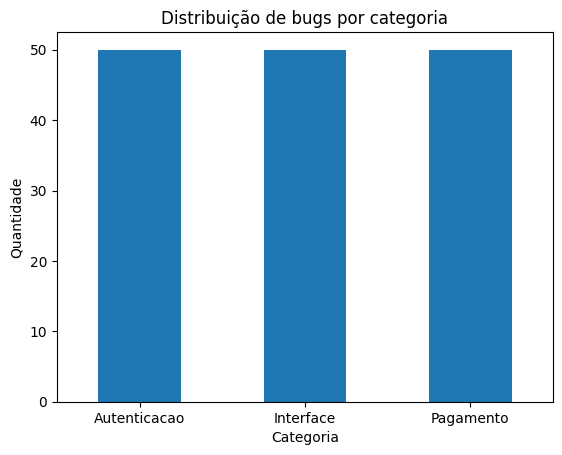

In [5]:
#data analysis
display(df.head())
print("Total de registros:", len(df))

print("Quantidade por categoria:")
print(df["categoria"].value_counts())

print("Valores ausentes:")
print(df.isnull().sum())

print("Descrições duplicadas:")
print(df["descricao"].duplicated().sum())

df["categoria"].value_counts().plot(
    kind="bar",
    title="Distribuição de bugs por categoria",
    xlabel="Categoria",
    ylabel="Quantidade"
)

plt.xticks(rotation=0)
plt.show()


In [6]:
#separation

X = df["descricao"]
y = df["categoria"]

X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Separação concluída!")

print("Dados de treinamento:", len(X_treino))
print("Dados de teste:", len(X_teste))

print("Distribuição das categorias no treinamento:")
print(y_treino.value_counts())

print("Distribuição das categorias no teste:")
print(y_teste.value_counts())


Separação concluída!
Dados de treinamento: 120
Dados de teste: 30
Distribuição das categorias no treinamento:
categoria
Autenticacao    40
Pagamento       40
Interface       40
Name: count, dtype: int64
Distribuição das categorias no teste:
categoria
Autenticacao    10
Pagamento       10
Interface       10
Name: count, dtype: int64


In [7]:
#pipeline

modelo = Pipeline([
    ("tfidf", TfidfVectorizer()),
    ("classificador", LogisticRegression(max_iter=1000))
])

print("Pipeline criado com sucesso!")


Pipeline criado com sucesso!


In [8]:
#training
modelo.fit(X_treino, y_treino)

print("Modelo treinado com sucesso!")
print("Categorias identificadas pelo modelo:")
print(modelo.classes_)


Modelo treinado com sucesso!
Categorias identificadas pelo modelo:
['Autenticacao' 'Interface' 'Pagamento']


Acurácia do modelo: 86.67%
Relatório de classificação:
              precision    recall  f1-score   support

Autenticacao       0.71      1.00      0.83        10
   Interface       1.00      0.90      0.95        10
   Pagamento       1.00      0.70      0.82        10

    accuracy                           0.87        30
   macro avg       0.90      0.87      0.87        30
weighted avg       0.90      0.87      0.87        30



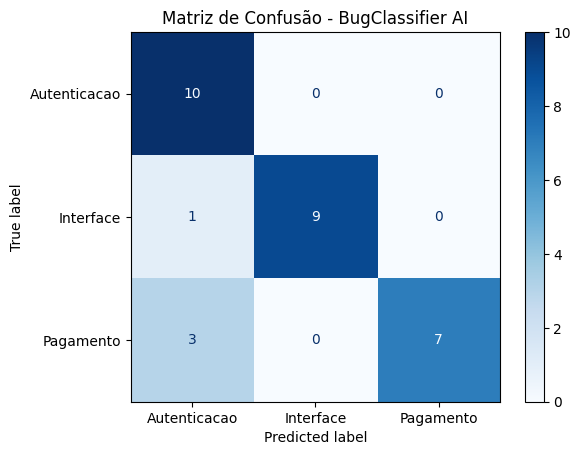

In [10]:
y_pred = modelo.predict(X_teste)

acuracia = accuracy_score(y_teste, y_pred)

print(f"Acurácia do modelo: {acuracia * 100:.2f}%")

print("Relatório de classificação:")
print(classification_report(y_teste, y_pred, zero_division=0))

matriz = confusion_matrix(y_teste, y_pred)

visualizacao = ConfusionMatrixDisplay(
    confusion_matrix=matriz,
    display_labels=modelo.classes_
)

visualizacao.plot(cmap="Blues", values_format="d")
plt.title("Matriz de Confusão - BugClassifier AI")
plt.show()


In [11]:
#classification
def classificar_bug(descricao, limite_confianca=0.70):

    if not isinstance(descricao, str) or not descricao.strip():
        raise ValueError("Informe uma descrição válida.")

    probabilidades = modelo.predict_proba([descricao])[0]

    indice_maior = probabilidades.argmax()

    maior_probabilidade = probabilidades[indice_maior]

    categoria_prevista = modelo.classes_[indice_maior]


    if maior_probabilidade >= limite_confianca:
        status = "Classificação automática"
    else:
        status = "Necessita de análise humana"

    resultado = {
        "descricao": descricao,
        "categoria": categoria_prevista,
        "probabilidade": round(float(maior_probabilidade) * 100, 2),
        "status": status
    }

    return resultado


In [12]:
#data test
novos_bugs = [
    "Não consigo acessar minha conta usando minha senha",
    "A página inicial está com os elementos desalinhados",
    "O pagamento via Pix não foi confirmado",
    "O aplicativo encerra minha sessão inesperadamente",
    "O botão de confirmação não responde ao clique",
    "Meu cartão foi cobrado mas o pedido não foi registrado"
]

for descricao in novos_bugs:

    resultado = classificar_bug(descricao)

    print("Descrição:", resultado["descricao"])
    print("Categoria:", resultado["categoria"])
    print("Probabilidade:", f'{resultado["probabilidade"]}%')
    print("Status:", resultado["status"])
    print("-" * 50)


Descrição: Não consigo acessar minha conta usando minha senha
Categoria: Autenticacao
Probabilidade: 84.56%
Status: Classificação automática
--------------------------------------------------
Descrição: A página inicial está com os elementos desalinhados
Categoria: Interface
Probabilidade: 77.47%
Status: Classificação automática
--------------------------------------------------
Descrição: O pagamento via Pix não foi confirmado
Categoria: Pagamento
Probabilidade: 79.67%
Status: Classificação automática
--------------------------------------------------
Descrição: O aplicativo encerra minha sessão inesperadamente
Categoria: Autenticacao
Probabilidade: 58.61%
Status: Necessita de análise humana
--------------------------------------------------
Descrição: O botão de confirmação não responde ao clique
Categoria: Interface
Probabilidade: 56.68%
Status: Necessita de análise humana
--------------------------------------------------
Descrição: Meu cartão foi cobrado mas o pedido não foi regis

In [14]:
#saving

joblib.dump(modelo, "bug_classifier.joblib")

print("Modelo salvo com sucesso!")

Modelo salvo com sucesso!


In [15]:
from google.colab import files

files.download("bug_classifier.joblib")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>